# Kalp Hastalığı – Veri Analizi
Veri seti: Heart Failure Prediction (fedesoriano, Kaggle). 5 farklı veri kaynağının birleşimi, 918 hasta.
Amaç: Veriyi tanımak, sınıf dağılımını ve tanımlayıcı istatistikleri incelemek, temizlenmesi gereken değerleri bulmak.

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
FIG = "../results/figures/"
TAB = "../results/tables/"

In [16]:
heart_raw = pd.read_csv("../data/raw/heart.csv")
symptom_raw = pd.read_csv("../data/raw/Symptom2Disease.csv")

print("Kalp verisi:", heart_raw.shape)
print("Belirti verisi:", symptom_raw.shape)

df = heart_raw   # analiz hücrelerinde kalp verisini df adıyla kullanıyoruz
df.head()

Kalp verisi: (918, 12)
Belirti verisi: (1200, 3)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [17]:
df.info()
print("\nEksik değer sayısı:\n", df.isna().sum())
print("\nTekrarlanan satır:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB

Eksik değer sayısı:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak        

| Sütun | Anlamı | Tip |
|---|---|---|
| Age | Yaş | Sayısal |
| Sex | Cinsiyet (M/F) | Kategorik |
| ChestPainType | Göğüs ağrısı: TA tipik angina, ATA atipik angina, NAP angina dışı ağrı, ASY belirtisiz | Kategorik |
| RestingBP | İstirahat kan basıncı (mm Hg) | Sayısal |
| Cholesterol | Serum kolesterol (mg/dl) | Sayısal |
| FastingBS | Açlık kan şekeri > 120 mg/dl (1/0) | İkili |
| RestingECG | İstirahat EKG: Normal, ST, LVH | Kategorik |
| MaxHR | Ulaşılan maksimum kalp hızı | Sayısal |
| ExerciseAngina | Egzersizle gelen göğüs ağrısı (Y/N) | Kategorik |
| Oldpeak | Egzersizle ST depresyonu | Sayısal |
| ST_Slope | ST segment eğimi: Up, Flat, Down | Kategorik |
| **HeartDisease** | **Hedef: 1 = kalp hastalığı var, 0 = yok** | İkili |

              Hasta sayısı  Oran (%)
HeartDisease                        
0                      410      44.7
1                      508      55.3


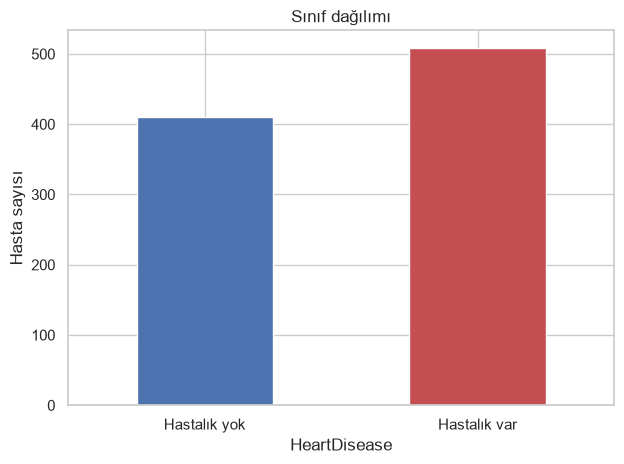

In [18]:
sinif = df["HeartDisease"].value_counts().sort_index()
print(pd.DataFrame({"Hasta sayısı": sinif, "Oran (%)": (sinif / len(df) * 100).round(1)}))

ax = sinif.rename({0: "Hastalık yok", 1: "Hastalık var"}).plot(kind="bar", color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Sınıf dağılımı"); ax.set_ylabel("Hasta sayısı")
plt.tight_layout(); plt.savefig(FIG + "kalp_01_sinif_dagilimi.png", dpi=150); plt.show()

In [19]:
SAYISAL = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
istat = pd.DataFrame({
    "Ortalama": df[SAYISAL].mean(),
    "Medyan": df[SAYISAL].median(),
    "Mod": df[SAYISAL].mode().iloc[0],
    "Std. sapma": df[SAYISAL].std(),
    "Min": df[SAYISAL].min(),
    "Maks": df[SAYISAL].max(),
}).round(2)
istat.to_csv(TAB + "kalp_tanimlayici_istatistikler.csv")
istat

,Ortalama,Medyan,Mod,Std. sapma,Min,Maks
Age,53.51,54.0,54.0,9.43,28.0,77.0
RestingBP,132.40,130.0,120.0,18.51,0.0,200.0
Cholesterol,198.80,223.0,0.0,109.38,0.0,603.0
MaxHR,136.81,138.0,150.0,25.46,60.0,202.0
Oldpeak,0.89,0.6,0.0,1.07,-2.6,6.2


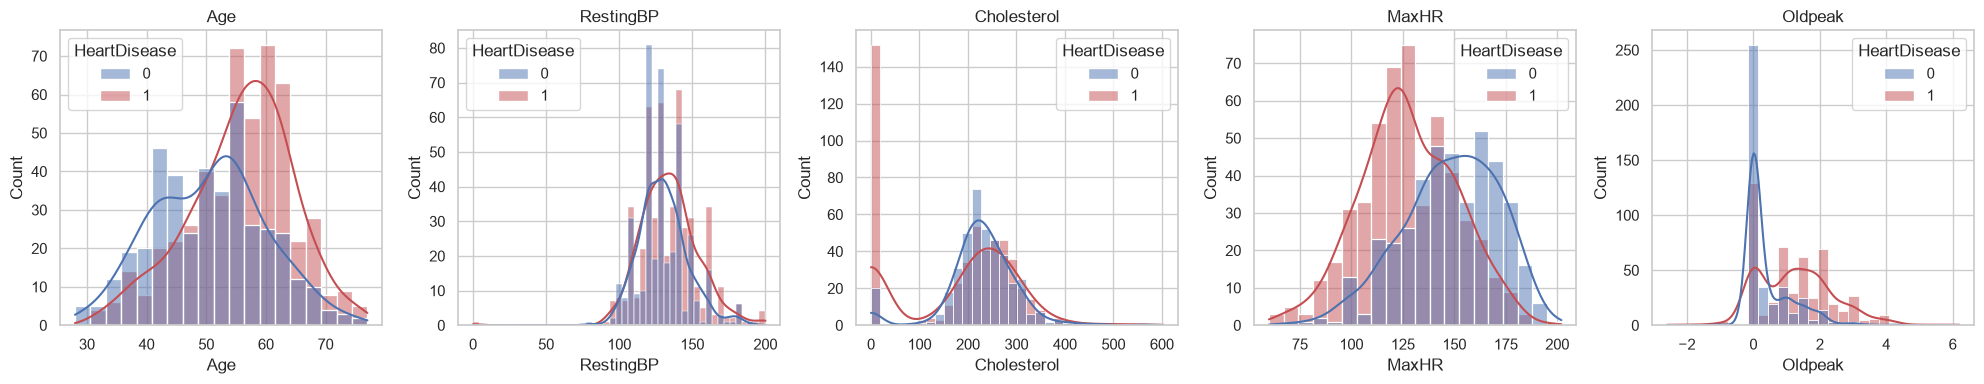

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, SAYISAL):
    sns.histplot(data=df, x=col, hue="HeartDisease", kde=True, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_title(col)
plt.tight_layout(); plt.savefig(FIG + "kalp_02_histogramlar.png", dpi=150); plt.show()

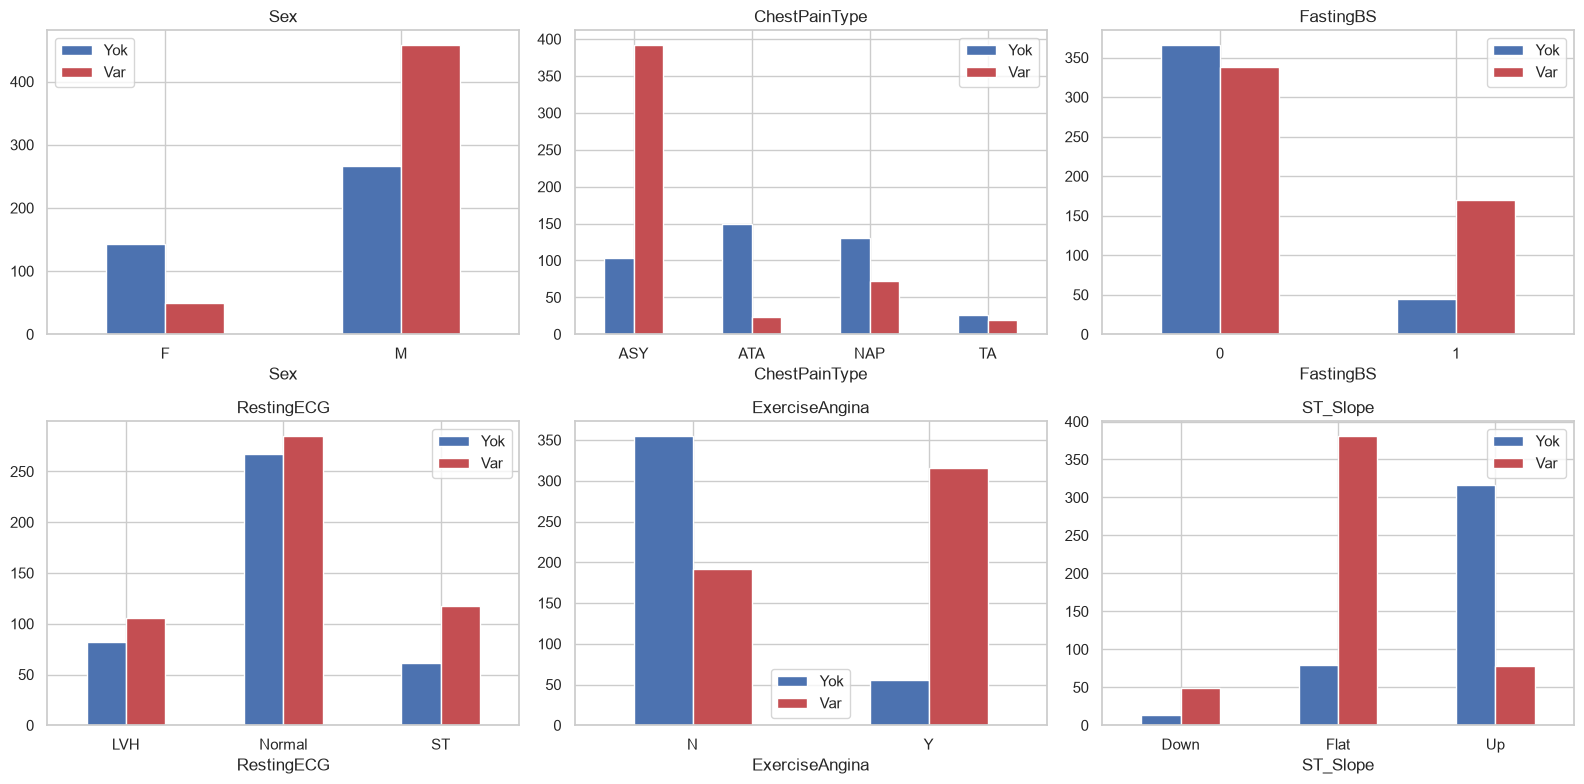

In [21]:
KATEGORIK = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, KATEGORIK):
    pd.crosstab(df[col], df["HeartDisease"]).plot(kind="bar", ax=ax, rot=0, color=["#4C72B0", "#C44E52"])
    ax.set_title(col); ax.legend(["Yok", "Var"])
plt.tight_layout(); plt.savefig(FIG + "kalp_03_kategorik.png", dpi=150); plt.show()

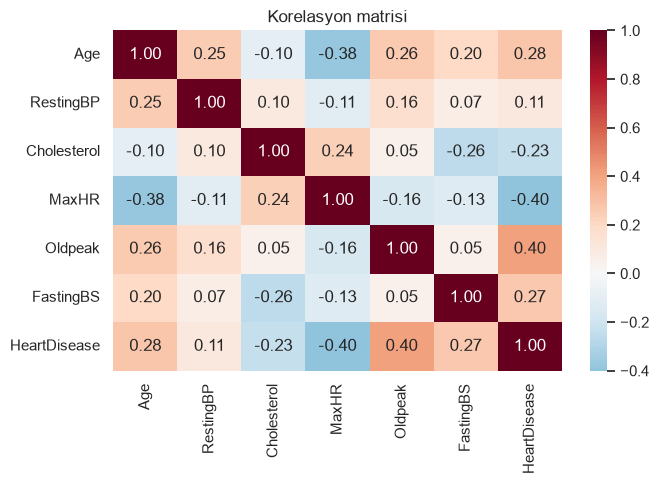

In [22]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[SAYISAL + ["FastingBS", "HeartDisease"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Korelasyon matrisi")
plt.tight_layout(); plt.savefig(FIG + "kalp_04_korelasyon.png", dpi=150); plt.show()

In [23]:
# Bronze: ham verinin olduğu gibi saklanan kopyası
heart_bronze = heart_raw.copy()
symptom_bronze = symptom_raw.copy()

heart_bronze.to_csv("../data/bronze/heart_bronze.csv", index=False)
symptom_bronze.to_csv("../data/bronze/symptom_bronze.csv", index=False)
print("Bronze katmanına kaydedildi.")

Bronze katmanına kaydedildi.


In [24]:
print("Değeri 0 olan kayıt sayısı:")
print((heart_bronze[["Age", "RestingBP", "Cholesterol", "MaxHR"]] == 0).sum())
print("\nNegatif Oldpeak sayısı:", (heart_bronze["Oldpeak"] < 0).sum())

Değeri 0 olan kayıt sayısı:
Age              0
RestingBP        1
Cholesterol    172
MaxHR            0
dtype: int64

Negatif Oldpeak sayısı: 13


In [25]:
kol_eksik = heart_bronze["Cholesterol"] == 0
print("Kolesterol = 0 olanlarda hastalık oranı: %.1f%%" % (heart_bronze.loc[kol_eksik, "HeartDisease"].mean() * 100))
print("Diğerlerinde hastalık oranı:             %.1f%%" % (heart_bronze.loc[~kol_eksik, "HeartDisease"].mean() * 100))

Kolesterol = 0 olanlarda hastalık oranı: 88.4%
Diğerlerinde hastalık oranı:             47.7%


In [26]:
silver = heart_bronze.copy()
gunluk = []   # rapor için ön işleme günlüğü

# 1) Kan basıncı 0: tek kayıt, fizyolojik olarak imkânsız → silinir
n = (silver["RestingBP"] == 0).sum()
silver = silver[silver["RestingBP"] != 0]
gunluk.append(("RestingBP = 0", n, "Kayıt silindi (fizyolojik olarak imkânsız, tek kayıt)"))

# 2) Kolesterol 0: gerçek eksik değer → NaN yapılır, eksiklik bilgisi ayrı sütunda tutulur
n = (silver["Cholesterol"] == 0).sum()
silver["Cholesterol_eksik"] = (silver["Cholesterol"] == 0).astype(int)
silver["Cholesterol"] = silver["Cholesterol"].replace(0, np.nan)
gunluk.append(("Cholesterol = 0", n, "NaN yapıldı; 'Cholesterol_eksik' sütunu eklendi; modelde medyanla doldurulacak"))

# 3) Negatif Oldpeak: ST yükselmesini ifade eder, klinik olarak mümkün → korunur
n = (silver["Oldpeak"] < 0).sum()
gunluk.append(("Oldpeak < 0", n, "Korundu (ST yükselmesi, klinik olarak mümkün)"))

# 4) Tekrarlanan satırlar
n = silver.duplicated().sum()
silver = silver.drop_duplicates()
gunluk.append(("Tekrarlanan satır", n, "Silindi"))

gunluk_df = pd.DataFrame(gunluk, columns=["Sorun", "Kayıt sayısı", "Yapılan işlem"])
gunluk_df.to_csv(TAB + "kalp_on_isleme_gunlugu.csv", index=False)
print("Bronze boyut:", heart_bronze.shape, "→ Silver boyut:", silver.shape)
gunluk_df

Bronze boyut: (918, 12) → Silver boyut: (917, 13)


,Sorun,Kayıt sayısı,Yapılan işlem
0,RestingBP = 0,1,"Kayıt silindi (fizyolojik olarak imkânsız, tek..."
1,Cholesterol = 0,171,NaN yapıldı; 'Cholesterol_eksik' sütunu eklend...
2,Oldpeak < 0,13,"Korundu (ST yükselmesi, klinik olarak mümkün)"
3,Tekrarlanan satır,0,Silindi


             Aykırı değer sayısı
Age                            0
RestingBP                     27
Cholesterol                   23
MaxHR                          2
Oldpeak                       16


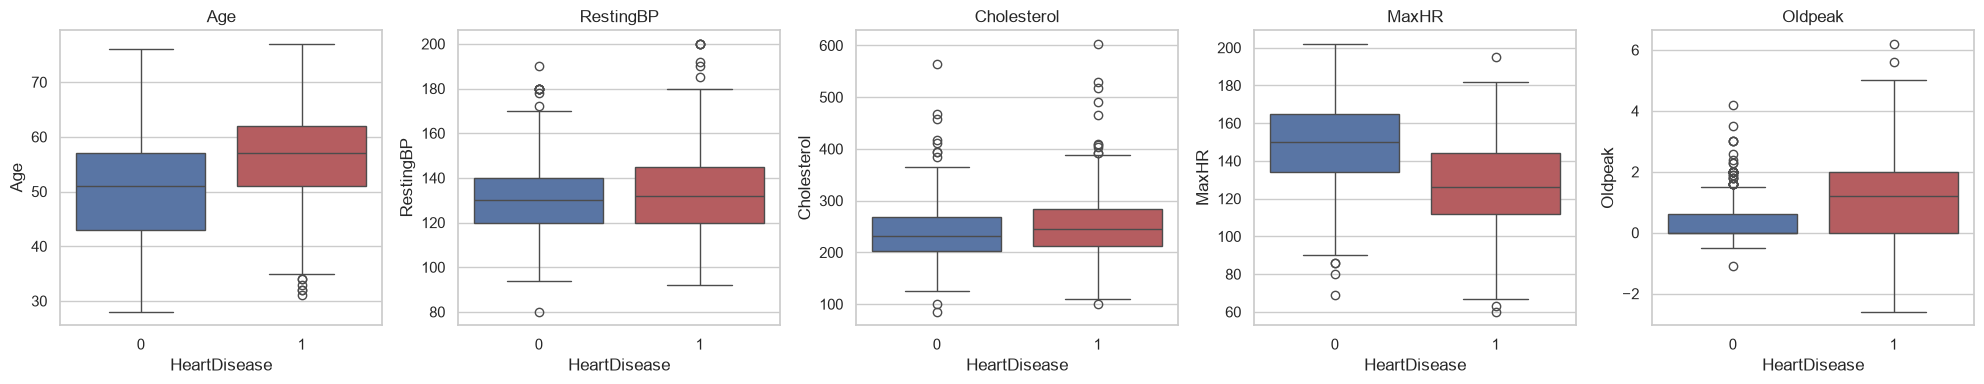

In [27]:
aykiri = {}
for col in SAYISAL:
    q1, q3 = silver[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    aykiri[col] = ((silver[col] < q1 - 1.5 * iqr) | (silver[col] > q3 + 1.5 * iqr)).sum()
aykiri_df = pd.Series(aykiri, name="Aykırı değer sayısı").to_frame()
aykiri_df.to_csv(TAB + "kalp_aykiri_degerler.csv")
print(aykiri_df)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, SAYISAL):
    sns.boxplot(data=silver, x="HeartDisease", y=col, hue="HeartDisease", ax=ax,
                palette=["#4C72B0", "#C44E52"], legend=False)
    ax.set_title(col)
plt.tight_layout(); plt.savefig(FIG + "kalp_05_kutu_grafikleri.png", dpi=150); plt.show()

In [28]:
istat_silver = pd.DataFrame({
    "Ortalama": silver[SAYISAL].mean(),
    "Medyan": silver[SAYISAL].median(),
    "Mod": silver[SAYISAL].mode().iloc[0],
    "Std. sapma": silver[SAYISAL].std(),
    "Min": silver[SAYISAL].min(),
    "Maks": silver[SAYISAL].max(),
}).round(2)
istat_silver.to_csv(TAB + "kalp_tanimlayici_istatistikler_temiz.csv")

silver.to_csv("../data/silver/heart_silver.csv", index=False)
print("Kaydedildi: data/silver/heart_silver.csv")
istat_silver

Kaydedildi: data/silver/heart_silver.csv


,Ortalama,Medyan,Mod,Std. sapma,Min,Maks
Age,53.51,54.0,54.0,9.44,28.0,77.0
RestingBP,132.54,130.0,120.0,18.00,80.0,200.0
Cholesterol,244.64,237.0,254.0,59.15,85.0,603.0
MaxHR,136.79,138.0,150.0,25.47,60.0,202.0
Oldpeak,0.89,0.6,0.0,1.07,-2.6,6.2
